# Tutorial 13: From Layout to Hamiltonian with ML

In [Tutorial 1](https://lfl-lab.github.io/SQuADDS/source/tutorials/Tutorial-1_Getting_Started_with_SQuADDS.html) and [Tutorial 2](https://lfl-lab.github.io/SQuADDS/source/tutorials/Tutorial-2_Simulate_interpolated_designs.html), checking a design against its Hamiltonian targets meant an Ansys Q3D run: a licence, a Windows machine and minutes per design. In this tutorial we walk through the same design flow, but replace the Q3D capacitance simulation with a machine-learning prediction that takes about a second. We then use it to check an interpolated design that nobody has simulated, and to query the new qubit and coupler families of SQuADDS.

**Note:** the ML models need the optional extras, `pip install "squadds[ml,gds]"`.

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

We'll use quantum-metal without its GUI in this tutorial, so let's tell it that before importing anything. We'll also silence the (many) deprecation warnings that quantum-metal and Shapely like to print.

In [2]:
import logging
import os
import warnings

os.environ.setdefault("QISKIT_METAL_HEADLESS", "1")
warnings.filterwarnings("ignore")
logging.getLogger("httpx").setLevel(logging.WARNING)

## The design problem

Let's say we want a transmon with

- a qubit frequency $f_q = 4$ GHz and an anharmonicity $\alpha = -200$ MHz,
- read out through a quarter-wave resonator at $f_r = 6.2$ GHz with $\kappa = 120$ kHz,
- with a qubit-resonator coupling $g = 70$ MHz.

Every one of these numbers except $f_r$ and $\kappa$ is set by **capacitance**. For a grounded transmon (an Xmon-style cross) with total capacitance $C_\Sigma$,

$$E_C = \frac{e^2}{2 C_\Sigma}, \qquad f_q \approx \sqrt{8 E_J E_C} - E_C, \qquad \alpha \approx -E_C ,$$

and the coupling grows with the claw-to-cross capacitance $C_g$ roughly as $g \propto (C_g / C_\Sigma)\, (E_J/E_C)^{1/4}$.

Instead of a Q3D run per candidate, we'll ask a model trained on about 45,000 Q3D simulations.

## Query the SQuADDS Database

Let's first find the closest qubit-cavity design in SQuADDS, exactly as in Tutorial 1.

In [3]:
from squadds import Analyzer, SQuADDS_DB

Importing SQuADDS (through scqubits) switches the inline figures to a vector format, so let's switch them back to PNG.

In [4]:
from matplotlib_inline.backend_inline import set_matplotlib_formats

set_matplotlib_formats("png")

In [5]:
db = SQuADDS_DB()
db.select_system(["qubit", "cavity_claw"])
db.select_qubit("TransmonCross")
db.select_cavity_claw("RouteMeander")
db.select_resonator_type("quarter")
db.show_selections()

Selected qubit:  TransmonCross
Selected cavity:  RouteMeander
Selected coupler to feedline:  CLT
Selected resonator type:  quarter
Selected system:  ['qubit', 'cavity_claw']


In [6]:
df = db.create_system_df()
analyzer = Analyzer(db)

Our Hamiltonian targets:

In [7]:
target_params = {
    "qubit_frequency_GHz": 4,
    "cavity_frequency_GHz": 6.2,
    "kappa_kHz": 120,
    "resonator_type": "quarter",
    "anharmonicity_MHz": -200,
    "g_MHz": 70,
}

In [8]:
results = analyzer.find_closest(target_params=target_params, num_top=3, metric="Euclidean", display=True)
results

Time taken to add the coupled H params: 1.3436923027038574 seconds


,index_qc,cross_to_ground,claw_to_ground,cross_to_claw,cross_to_cross,claw_to_claw,ground_to_ground,units_qubit,setup,renderer_options,...,resonator_type,design_tool_cavity_claw,notes_cavity_claw,contributor,design_options,EC,EJ,qubit_frequency_GHz,anharmonicity_MHz,g_MHz
16535,1441,112.70740,107.65111,5.75841,112.70740,113.99245,274.49373,fF,"{'name': 'sweep_setup', 'reuse_selected_design...","{'Lj': '10nH', 'Cj': 0, '_Rj': 0, 'max_mesh_le...",...,quarter,qiskit-metal,{},"{""group"":""LFL"",""PI"":""Eli Levenson-Falk, PhD"",""...",{'cavity_claw_options': {'coupler_type': 'CLT'...,0.163509,12.278081,3.836546,-182.146811,67.608428
9252,812,100.41444,99.80185,5.38260,100.41444,105.76081,251.82560,fF,"{'name': 'sweep_setup', 'reuse_selected_design...","{'Lj': '10nH', 'Cj': 0, '_Rj': 0, 'max_mesh_le...",...,quarter,qiskit-metal,{},"{""group"":""LFL"",""PI"":""Eli Levenson-Falk, PhD"",""...",{'cavity_claw_options': {'coupler_type': 'CLT'...,0.183089,12.278081,4.048674,-205.519307,69.751635
13522,1180,105.83609,103.57639,5.68548,105.83609,109.80541,261.84982,fF,"{'name': 'sweep_setup', 'reuse_selected_design...","{'Lj': '10nH', 'Cj': 0, '_Rj': 0, 'max_mesh_le...",...,quarter,qiskit-metal,{},"{""group"":""LFL"",""PI"":""Eli Levenson-Falk, PhD"",""...",{'cavity_claw_options': {'coupler_type': 'CLT'...,0.173690,12.278081,3.948501,-194.261783,70.474117


Let's keep the closest design and look at its own (Q3D-based) numbers. `EC` and `EJ` are in GHz, and `cross_to_claw` / `cross_to_ground` are the capacitances (fF) that Q3D gave the contributor of this row.

In [9]:
best = results.iloc[0]
best[["qubit_frequency_GHz", "anharmonicity_MHz", "g_MHz", "cavity_frequency_GHz", "EC", "EJ",
      "cross_to_claw", "cross_to_ground"]]

qubit_frequency_GHz       3.836546
anharmonicity_MHz      -182.146811
g_MHz                    67.608428
cavity_frequency_GHz      6.429384
EC                        0.163509
EJ                       12.278081
cross_to_claw              5.75841
cross_to_ground           112.7074
Name: 16535, dtype: object

The qubit part of the design lives in `design_options_qubit`:

In [10]:
qubit_options = best["design_options_qubit"]
qubit_options

{'pos_x': '-1500um',
 'pos_y': '1200um',
 'orientation': '-90',
 'chip': 'main',
 'layer': '1',
 'connection_pads': {'readout': {'connector_type': '0',
   'claw_length': '210um',
   'ground_spacing': '10um',
   'claw_width': '15um',
   'claw_gap': '5.1um',
   'claw_cpw_length': '40um',
   'claw_cpw_width': '10um',
   'connector_location': '90'}},
 'cross_width': '30um',
 'cross_length': '230um',
 'cross_gap': '30um',
 'hfss_inductance': 9.7e-09,
 'hfss_capacitance': 0,
 'hfss_resistance': 0,
 'hfss_mesh_kw_jj': 7e-06,
 'q3d_inductance': '10nH',
 'q3d_capacitance': 0,
 'q3d_resistance': 0,
 'q3d_mesh_kw_jj': 7e-06,
 'gds_cell_name': 'my_other_junction',
 'aedt_q3d_inductance': 1e-08,
 'aedt_q3d_capacitance': 0,
 'aedt_hfss_inductance': 9.7e-09,
 'aedt_hfss_capacitance': 0}

## Render the design in quantum-metal

We pass these options to a `TransmonCross` (as in Tutorial 1) and rebuild the design. No GUI window opens since we are running headless.

In [11]:
from qiskit_metal import designs
from qiskit_metal.qlibrary.qubits.transmon_cross import TransmonCross

In [12]:
design = designs.DesignPlanar({}, overwrite_enabled=True)
qubit = TransmonCross(design, "qubit", options=qubit_options)
design.rebuild()

The capacitance models read a GDS with two layers: the **ground plane on layer 1/0** and **every signal conductor on layer 1/10**. Each connected body is one conductor, and nets are never merged. `render_gds` exports a quantum-metal design in that convention. It is the same rendering `MLSimulator` uses internally.

In [13]:
from pathlib import Path

from squadds.ml.capacitance.bridge import render_gds

Path("tutorial13_files").mkdir(exist_ok=True)
qubit_gds = render_gds(design, "tutorial13_files/transmon_cross.gds")
qubit_gds

PosixPath('tutorial13_files/transmon_cross.gds')

## Look at the metal (and the ports) first

Since the input to the model is the layout, let's look at what the model sees before we ask for any number. `prepare_layout` reads a GDS exactly the way the predictor does: the ground is one net, and every conductor body gets a name `C1`, `C2`, ... in file order.

In [14]:
from squadds.ml.capacitance import prepare_layout

qubit_layout = prepare_layout(str(qubit_gds))
qubit_layout.names

['C1', 'C2']

`C1` and `C2` are not very telling, so here is a small helper that names every body after the quantum-metal shape it overlaps the most.

In [15]:
from shapely import affinity


def name_conductors(design, layout):
    """{predictor name: Qiskit Metal shape name} for every conductor body."""
    shapes = {}
    for table in ("poly", "path"):
        df = design.qgeometry.tables[table]
        for row in df[~df["subtract"].astype(bool) & ~df["helper"].astype(bool)].itertuples():
            g = row.geometry if table == "poly" else row.geometry.buffer(row.width / 2, cap_style=2)
            shapes[row.name] = affinity.scale(g, 1000, 1000, origin=(0, 0))  # Metal mm -> GDS µm
    names = {}
    for name, body in zip(layout.names, layout.conductors):
        names[name] = max(shapes, key=lambda s: body.intersection(shapes[s]).area)
    return names

And one that draws the ground in grey (its etch in white), every conductor in its own color, and the quantum-metal **pins** of the component as red arrows. The pins are the ports, where a resonator, a feed line or a bus attaches in the full chip.

In [16]:
import matplotlib.pyplot as plt


def plot_layout(layout, names=None, pins=None, title="", ax=None):
    """Ground in grey, every conductor in its own color, and the component's pins (ports) as red arrows."""
    ax = ax or plt.subplots(figsize=(5.5, 5.5))[1]
    for poly in getattr(layout.ground, "geoms", [layout.ground]):
        ax.fill(*poly.exterior.xy, color="0.82", lw=0)
        for hole in poly.interiors:
            ax.fill(*hole.xy, color="white", lw=0)
    for k, (name, body) in enumerate(zip(layout.names, layout.conductors)):
        for i, poly in enumerate(getattr(body, "geoms", [body])):
            label = f"{name}: {(names or {}).get(name, name)}" if i == 0 else None
            ax.fill(*poly.exterior.xy, color=plt.cm.tab10(k % 10), lw=0, label=label)
    for pin_name, pin in (pins or {}).items():
        (x, y), (dx, dy) = 1e3 * pin["middle"], 60 * pin["normal"]
        ax.annotate(f"port '{pin_name}'", xy=(x, y), xytext=(x + dx, y + dy), color="crimson", fontsize=9,
                    arrowprops=dict(arrowstyle="<-", color="crimson"))
    ax.set_aspect("equal")
    ax.set(xlabel="x (µm)", ylabel="y (µm)", title=title)
    ax.legend(loc="lower left", fontsize=8)
    return ax

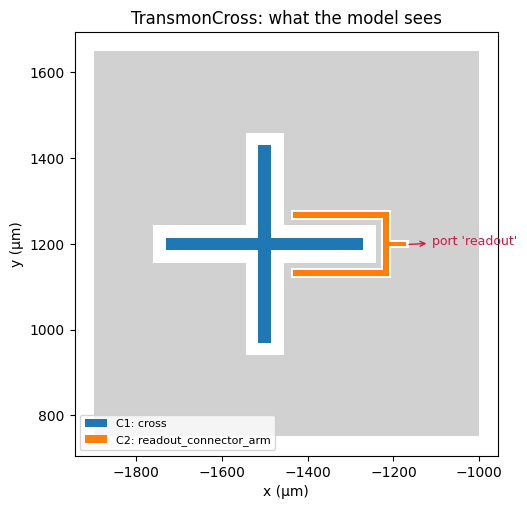

In [17]:
qubit_names = name_conductors(design, qubit_layout)
plot_layout(qubit_layout, qubit_names, qubit.pins, title="TransmonCross: what the model sees");

Great! Two conductors and the ground: the **cross** (the qubit island) and the **claw** of the readout connector. The junction goes from the cross to ground and is not part of the capacitance problem. The `readout` port is where the resonator attaches. That is the metal we expect, so now we can ask for numbers.

## Predict the capacitance matrix with `MLSimulator`

`MLSimulator` has the same call and the same result shape as the capacitance path of `AnsysSimulator` (Tutorial 2), so the rest of the SQuADDS workflow does not care where the numbers came from. Every result carries a **fidelity label**, `"ml:QCap"` or `"ml:QCap-Fast"`, so a prediction can never be mistaken for a simulation.

**How far can we trust it?** The default model, `QCap`, runs two thin-film method-of-moments field solves and corrects them with a small graph neural network. It was trained on **all** the data, so it has no held-out score of its own. The paper's version of it (same recipe, networks trained on the TRAIN split only) scores against Q3D (median relative error over the coupling entries, with MAE and RMSE):

| test set | median % | MAE (fF) | RMSE (fF) |
|---|---|---|---|
| test, families seen in training (4,009 layouts) | 0.177 % | 0.0203 | 0.025 |
| a whole family held out of training (4,071 layouts) | 0.408 % | 0.049 | 0.059 |
| zero-shot, unseen kinds of layouts (1,878 layouts) | 0.587 % | 1.092 | 1.152 |
| fresh check of QCap on 39 new layouts | 1.05 % | 0.132 | 0.188 |

It costs about 1 s per small component (median 0.845 s on 2 CPUs of an x86 cluster node, 1.37 s on an Apple M5 Pro laptop for up to 4 conductors). It was trained on one stack: silicon ($\varepsilon_r = 11.45$), 350 µm thick, zero-thickness metal. For another substrate, pass `eps_r` and `thickness_um` to `predict`: `QCap` then solves its physics prior on your stack.

**Note:** if you have a local copy of the models, point `SQUADDS_CAPML_MODELS` at its folder and nothing is downloaded.

In [18]:
from squadds.ml.capacitance.bridge import MLSimulator

In [19]:
ml = MLSimulator()
ml

MLSimulator(model='QCap')

We can hand it the quantum-metal component directly:

In [20]:
ml_result = ml.predict(qubit)
ml_result["fidelity"], ml_result["timing"]

('ml:QCap',
 {'render_s': 0.007670043996768072,
  'prepare_s': 1.1577998520806432e-05,
  'load_s': 0.6325546239968389,
  'geometry_s': 0.4905749980098335,
  'prior_s': 1.8774226699897554,
  'prior_levels_s': {'1.5': 0.9462087409920059, '3': 0.9275481049990049},
  'network_s': 0.005776858000899665,
  'total_s': 2.3737745260004885,
  'cache_hits': {'embedding': False, 'prior': False},
  'threads': 2,
  'wall_s': 8.11429808298999})

The first call of a session is slow: it loads the model and compiles the numerical kernels once (`load_s` and most of `geometry_s` above). Let's ask again. SQuADDS remembers layouts it has already seen, so a repeated design is answered from a cache almost instantly. A **new** layout takes about a second, as we'll see below.

In [21]:
ml_result = ml.predict(qubit)
round(ml_result["timing"]["wall_s"], 2)

0.03

The result has the familiar `design` / `sim_options` / `sim_results` keys of `AnsysSimulator`, with the `sim_results` named just like the SQuADDS database rows:

In [22]:
ml_result["sim_results"]

{'cross_to_cross': 120.95360565185547,
 'cross_to_claw': 5.7873616218566895,
 'cross_to_ground': 113.3360824584961,
 'claw_to_claw': 114.9999771118164,
 'claw_to_ground': 108.2668685913086,
 'ground_to_ground': 270.2359924316406,
 'maxwell_matrix': {'C_G_G': 270.2359924316406,
  'C_G_S': -113.3360824584961,
  'C_G_N': -108.2668685913086,
  'C_S_G': -113.3360824584961,
  'C_S_S': 120.95360565185547,
  'C_S_N': -5.7873616218566895,
  'C_N_G': -108.2668685913086,
  'C_N_S': -5.7873616218566895,
  'C_N_N': 114.9999771118164},
 'units': 'fF'}

It also tells us whether the predicted matrix passed its physics checks (symmetry, signs, closure, positive definiteness) and whether anything looked unusual about the layout:

In [23]:
ml_result["checks"], ml_result["warnings"]

({'symmetric_max_abs': 0.0,
  'symmetric': True,
  'diagonal_positive': True,
  'offdiag_all_negative': True,
  'closure_min_row_sum': 0.945746898651123,
  'closure': True,
  'signal_block_min_eig': 111.46872118089837,
  'positive_definite': True,
  'passed': True},
 [])

The full Maxwell matrix (fF) is in `sim_results["maxwell_matrix"]`, keyed by the conductor labels. Let's put it in a DataFrame with readable names. The diagonal entries are positive self capacitances, and the off-diagonal entries are $-C^{\rm mutual}_{ij}$.

In [24]:
import pandas as pd


def maxwell_df(result):
    """The signed Maxwell matrix (fF) of an MLSimulator result, named like the SQuADDS sim_results."""
    nets = result["net_names"]
    M = result["sim_results"]["maxwell_matrix"]
    names = list(nets.values())
    return pd.DataFrame([[M[f"C_{a}_{b}"] for b in nets] for a in nets], index=names, columns=names)


maxwell_df(ml_result).round(3)

,ground,cross,claw
ground,270.236,-113.336,-108.267
cross,-113.336,120.954,-5.787
claw,-108.267,-5.787,115.000


## How close is it to Q3D?

This design **is** in the database, so we can compare the prediction with the row's own Q3D numbers. Here is a helper that lines them up in fF and in %. It summarizes the mutual (off-diagonal) entries with the median relative error, the MAE and the RMSE, the metric of the accuracy table above.

In [25]:
import numpy as np


def compare(row, result):
    """Q3D (database row) vs ML for every capacitance both carry, in fF and in %."""
    sr = result["sim_results"]
    keys = [k for k in sr if k in row.index and k not in ("units", "maxwell_matrix") and pd.notna(row[k])]
    out = pd.DataFrame({"Q3D (fF)": [float(row[k]) for k in keys], "ML (fF)": [sr[k] for k in keys]}, index=keys)
    out["ML - Q3D (fF)"] = out["ML (fF)"] - out["Q3D (fF)"]
    out["ML - Q3D (%)"] = 100 * out["ML - Q3D (fF)"] / out["Q3D (fF)"]
    mutual = [k for k in keys if k.split("_to_")[0] != k.split("_to_")[1]]
    d = out.loc[mutual, "ML - Q3D (fF)"]
    pct = 100 * (d / out.loc[mutual, "Q3D (fF)"]).abs()
    print(f"mutual entries: median {pct.median():.2f} % | MAE {d.abs().mean():.3f} fF | "
          f"RMSE {np.sqrt((d**2).mean()):.3f} fF | n = {len(mutual)}")
    return out.round(3)

In [26]:
compare(best, ml_result)

mutual entries: median 0.56 % | MAE 0.424 fF | RMSE 0.508 fF | n = 3


,Q3D (fF),ML (fF),ML - Q3D (fF),ML - Q3D (%)
cross_to_cross,112.707,120.954,8.246,7.316
cross_to_claw,5.758,5.787,0.029,0.503
cross_to_ground,112.707,113.336,0.629,0.558
claw_to_claw,113.992,115.000,1.008,0.884
claw_to_ground,107.651,108.267,0.616,0.572
ground_to_ground,274.494,270.236,-4.258,-1.551


The coupling we care about most, cross to claw, agrees closely with Q3D. Keep in mind that this is **one** design, so it is a sanity check, not an accuracy score (the table above is the accuracy score). The comparison is also not quite like for like.

<details>
<summary><b>Why this comparison is not like for like</b></summary>

- The SQuADDS `TransmonCross` rows were simulated by their contributor with their own Q3D setup. Their rows record no layer stack. The quantum-metal / SQuADDS default substrate is 750 µm thick, while the model serves 350 µm, so the difference above mixes the model error with this stack difference.
- The rendered chip is not the contributor's chip either: `render_gds` draws a square ground domain around the component. Entries that involve the ground feel that most. The cross-to-claw coupling is the most like-for-like number.
- In these database rows `cross_to_cross` is stored equal to `cross_to_ground`, so it is not the Maxwell diagonal the model predicts. That is why the self terms are left out of the summary line. (SQuADDS builds the `TransmonCross` $C_\Sigma$ from `cross_to_ground` and `cross_to_claw`, so the Hamiltonian below is not affected.)
- These `TransmonCross` geometries are not in the model's training data (the planar capacitance dataset has its own `Xmon` family, which we'll meet below).

</details>

## From capacitance to the Hamiltonian

Now let's turn the prediction into Hamiltonian parameters with the same functions SQuADDS uses for Q3D rows (`squadds.calcs.transmon_cross`). For the `TransmonCross`, SQuADDS uses $C_\Sigma = C_{\rm cross,ground} + C_{\rm cross,claw}$, so

$$E_C = \frac{e^2}{2\,(C_{\rm cross,ground} + C_{\rm cross,claw})} .$$

We keep the Josephson energy $E_J$ that SQuADDS picked for our target (the `EJ` column), get $f_q$ and $\alpha$ from scqubits, and compute $g$ from the capacitance matrix with the resonator frequency of the closest design:

$$g = \frac{C_g}{\sqrt{C_\Sigma}} \sqrt{\frac{\hbar\, \omega_r\, e^2}{\det C}} \left(\frac{E_J}{8 E_C}\right)^{1/4} \Big/ \hbar .$$

In [27]:
from squadds.calcs.transmon_cross import get_transmon_E01_alpha
from squadds.ml.capacitance.bridge import EC_MHz, g_MHz

In [28]:
EJ = float(best["EJ"])  # GHz
f_r = float(best["cavity_frequency_GHz"])
EC_ml = EC_MHz(ml_result)  # MHz
f_q_ml, alpha_ml = get_transmon_E01_alpha(EJ, EC_ml / 1e3)
g_ml = g_MHz(ml_result, EJ_GHz=EJ, f_r_GHz=f_r, res_type="quarter")

Let's line up the target, the database row (Q3D) and the ML prediction:

In [29]:
hamiltonian = pd.DataFrame(
    {
        "target": [None, target_params["qubit_frequency_GHz"], target_params["anharmonicity_MHz"], target_params["g_MHz"]],
        "closest design, Q3D": [1e3 * best["EC"], best["qubit_frequency_GHz"], best["anharmonicity_MHz"], best["g_MHz"]],
        "closest design, ML": [EC_ml, f_q_ml, alpha_ml, g_ml],
    },
    index=["E_C (MHz)", "f_q (GHz)", "alpha (MHz)", "g (MHz)"],
)
hamiltonian.round(3)

,target,"closest design, Q3D","closest design, ML"
E_C (MHz),NaN,163.509,162.606
f_q (GHz),4.0,3.837,3.826
alpha (MHz),-200.0,-182.147,-181.076
g (MHz),70.0,67.608,67.664


Awesome! In about a second we went from a layout to the qubit's Hamiltonian, and it agrees with what Q3D told the database within the differences we saw in the capacitances. Let's plot the comparison:

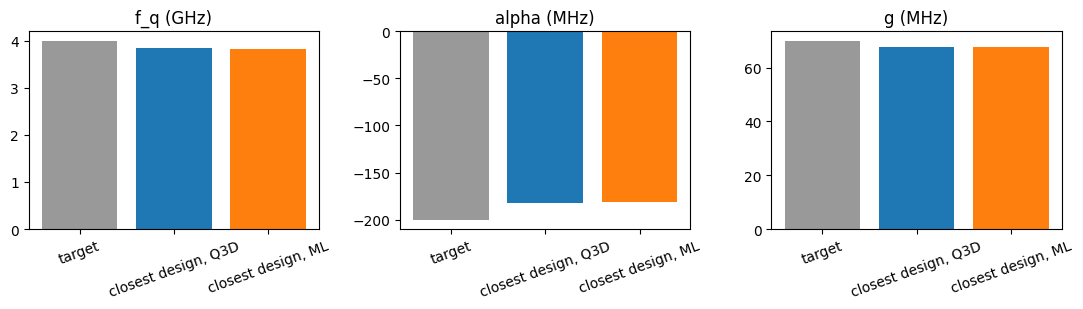

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, key in zip(axes, ["f_q (GHz)", "alpha (MHz)", "g (MHz)"]):
    vals = hamiltonian.loc[key]
    ax.bar(vals.index, vals.values, color=["0.6", "tab:blue", "tab:orange"])
    ax.set_title(key)
    ax.tick_params(axis="x", rotation=20)
fig.tight_layout()

## An interpolated design that nobody has simulated

The closest design is never exactly on target, so Tutorial 1 used the physics-inspired `ScalingInterpolator` to scale the geometry towards our targets. That gives a **new** design, and in Tutorial 2 the next step was a Q3D run to check it. Let's check it with the model instead.

In [31]:
from squadds.interpolations.physics import ScalingInterpolator

In [32]:
interpolator = ScalingInterpolator(analyzer, target_params)
design_df = interpolator.get_design()
design_df

Kappa scaling: 1.0025568750809213
g scaling: 0.9969935576236629
alpha scaling: 1.007757814178385
resonator scaling: 1.0055694290983872


,coupler_type,design_options_qubit,design_options_cavity_claw,setup_qubit,setup_cavity_claw,design_options
0,CLT,"{'pos_x': '-1500um', 'pos_y': '1200um', 'orien...",{'claw_opts': {'connection_pads': {'readout': ...,None,"{'name': 'sweep_setup', 'reuse_selected_design...",{'cavity_claw_options': {'coupler_type': 'CLT'...


The interpolated row holds the whole qubit-cavity system. `MLSimulator` predicts single components, so we hand `Analyzer.predict_capacitance` the qubit part and tell it which component class to build:

In [33]:
interpolated_qubit = pd.DataFrame(
    [{"design_options": design_df.iloc[0]["design_options_qubit"], "component_class": "TransmonCross"}]
)
interpolated_ml = analyzer.predict_capacitance(interpolated_qubit)
interpolated_ml.filter(regex="cross_to_claw_ml|cross_to_ground_ml|fidelity|ml_total_s")

,cross_to_claw_ml,cross_to_ground_ml,fidelity,ml_total_s
0,5.313089,103.74128,ml:QCap,1.381011


Before we trust its numbers, let's look at the interpolated cross next to the closest one. We'll wrap the render-and-plot steps from above in one small function, since we'll use it a few more times.

In [34]:
from squadds.ml.capacitance.bridge import build_component


def look_at(component, title, ax=None):
    """Render a component to GDS, then plot its metal and ports (returns the GDS path)."""
    gds = render_gds(component.design, Path("tutorial13_files") / (title.replace(" ", "_") + ".gds"))
    layout = prepare_layout(str(gds))
    plot_layout(layout, name_conductors(component.design, layout), component.pins, title=title, ax=ax)
    return gds

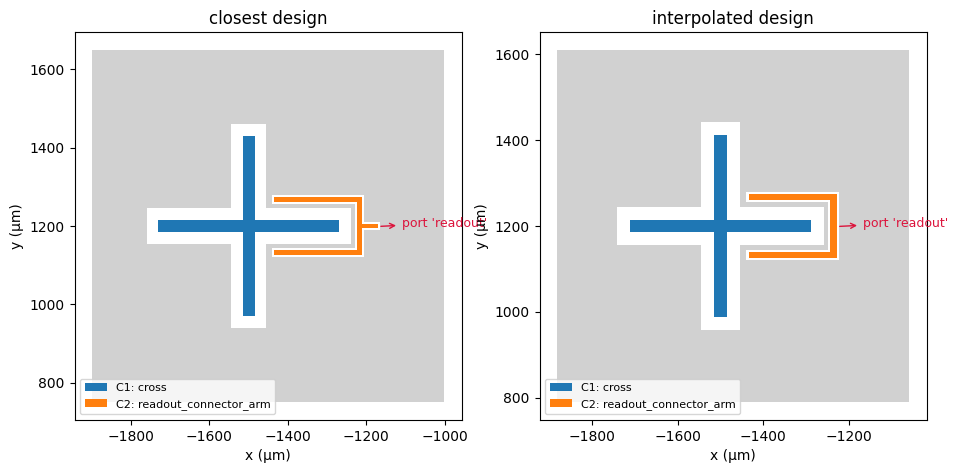

In [35]:
interpolated_component = build_component(interpolated_qubit.iloc[0])
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
look_at(qubit, "closest design", ax=axes[0])
look_at(interpolated_component, "interpolated design", ax=axes[1]);

Now the Hamiltonian of the interpolated design, with the same $E_J$:

In [36]:
interpolated_result = interpolated_ml.iloc[0]["ml_result"]
EC_interp = EC_MHz(interpolated_result)
f_q_interp, alpha_interp = get_transmon_E01_alpha(EJ, EC_interp / 1e3)
g_interp = g_MHz(interpolated_result, EJ_GHz=EJ, f_r_GHz=target_params["cavity_frequency_GHz"], res_type="quarter")
hamiltonian["interpolated design, ML"] = [EC_interp, f_q_interp, alpha_interp, g_interp]
hamiltonian.round(3)

,target,"closest design, Q3D","closest design, ML","interpolated design, ML"
E_C (MHz),NaN,163.509,162.606,177.620
f_q (GHz),4.0,3.837,3.826,3.991
alpha (MHz),-200.0,-182.147,-181.076,-198.960
g (MHz),70.0,67.608,67.664,64.058


Interesting! The interpolation pulled $f_q$ and $\alpha$ right onto our targets, but by the model's numbers $g$ came out a few MHz short of 70 MHz. That is exactly the kind of thing we want to catch *before* we spend a Q3D run (a slightly longer claw would be our next try).

This check used to need a Q3D run per candidate. Now that it takes about a second, we can check every candidate we are curious about, and keep the Q3D (or Palace) runs for the one design we are about to fabricate.

## New families: the planar capacitance dataset

The models were trained on the **planar capacitance dataset** ([Tutorial 12](https://lfl-lab.github.io/SQuADDS/source/tutorials/Tutorial-12_Planar_Capacitance_Families_in_SQuADDS.html)): about 45,000 Q3D-labelled layouts of interdigital, concentric, star and shielded capacitors, Xmon and `TransmonPocket` qubits and more, every one with its full capacitance matrix. SQuADDS can show these rows in its usual format as a second data source. It is on by default, and a local copy works too, pointed to by the environment variable `SQUADDS_PLANAR_CAP_DATA`.

In [37]:
db = SQuADDS_DB(sources=("default", "planar_capacitance"))
db.enabled_sources()

['default', 'planar_capacitance']

The new configurations show up next to the existing ones:

In [38]:
db.get_configs()

['qubit-TransmonCross-cap_matrix',
 'cavity_claw-RouteMeander-eigenmode',
 'coupler-NCap-cap_matrix',
 'coupler-CapNInterdigitalTee-cap_matrix',
 'coupler-GeneralizedCapNInterdigital-cap_matrix',
 'coupler-GeneralizedCapConcentric-cap_matrix',
 'coupler-GeneralizedCapStar-cap_matrix',
 'coupler-ShieldedCapConcentric-cap_matrix',
 'qubit-Xmon-cap_matrix',
 'qubit-TransmonPocket-cap_matrix']


### An Xmon with a target frequency and anharmonicity

The `Xmon` rows are a cross in a ground pocket with one or two claws. For these, SQuADDS takes $C_\Sigma$ as the full Maxwell diagonal of the cross, so a second claw is counted too.

In [39]:
db.unselect_all()
db.select_system("qubit")
db.select_qubit("Xmon")
xmon_df = db.create_system_df()
xmon_df.shape

(197, 41)

In [40]:
analyzer = Analyzer(db)
xmon_results = analyzer.find_closest({"qubit_frequency_GHz": 4.5, "anharmonicity_MHz": -200}, num_top=3)
xmon_results[["design_id", "qubit_frequency_GHz", "anharmonicity_MHz", "EC", "C_sigma_fF", "cross_to_claw"]]

,design_id,qubit_frequency_GHz,anharmonicity_MHz,EC,C_sigma_fF,cross_to_claw
32,ref/exp13/q3d_cap_0563,4.505992,-200.608575,0.181315,106.832206,6.345272
64,ref/exp13/q3d_cap_0632,4.509329,-200.938054,0.181596,106.666675,1.557704
95,ref/exp13/q3d_cap_0673,4.483355,-198.382118,0.179415,107.963389,1.768689


Let's look at the closest Xmon first. `build_component` rebuilds a database row with its quantum-metal class:

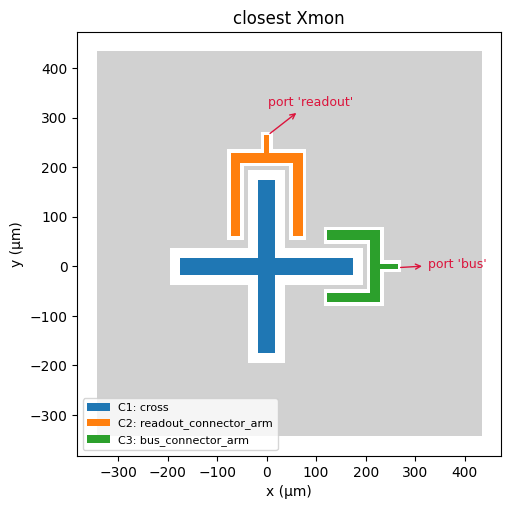

In [41]:
best_xmon = xmon_results.iloc[0]
look_at(build_component(best_xmon), "closest Xmon");

And now the prediction, with exactly the call we would use for `AnsysSimulator(analyzer, best_device).simulate()` in Tutorial 2:

In [42]:
xmon_ml = MLSimulator(analyzer, best_xmon).simulate()
xmon_ml["fidelity"], round(xmon_ml["timing"]["wall_s"], 2)

('ml:QCap', 1.8)

In [43]:
compare(best_xmon, xmon_ml)

mutual entries: median 0.49 % | MAE 0.247 fF | RMSE 0.348 fF | n = 6


,Q3D (fF),ML (fF),ML - Q3D (fF),ML - Q3D (%)
cross_to_cross,106.832,107.270,0.437,0.409
cross_to_claw,6.345,6.329,-0.016,-0.249
cross_to_bus_claw,3.386,3.368,-0.018,-0.519
cross_to_ground,95.552,95.991,0.438,0.459
claw_to_claw,88.970,88.972,0.003,0.003
claw_to_bus_claw,0.300,0.294,-0.006,-1.895
claw_to_ground,81.752,81.381,-0.371,-0.454
bus_claw_to_bus_claw,66.120,65.814,-0.306,-0.462
bus_claw_to_ground,62.008,61.378,-0.630,-1.017
ground_to_ground,279.653,277.604,-2.049,-0.733


**Careful:** every row of the planar capacitance dataset was part of QCap's training data, so this agreement is a consistency check of the plumbing (rows, rendering, naming), not a measure of accuracy. For accuracy, look at the table further up.

Here is the charging energy from the predicted matrix, with every claw included:

In [44]:
from squadds.ml.capacitance.bridge import EC_MHz_from_matrix

C_xmon = maxwell_df(xmon_ml)
EC_MHz_from_matrix(C_xmon.values, C_xmon.index, "cross"), 1e3 * best_xmon["EC"]

(180.57507032099102, 181.31451147234225)

### A floating transmon: `TransmonPocket`

A `TransmonPocket` has two pads and no grounded island, so the qubit is the **differential** mode of the two pads. With the coupler pads held at ground (their resonators are much larger capacitors),

$$\frac{1}{C_{\rm eff}} = (C^{-1})_{11} + (C^{-1})_{22} - 2\,(C^{-1})_{12}, \qquad E_C = \frac{e^2}{2 C_{\rm eff}},$$

where $C$ is the two-pad block of the Maxwell matrix. SQuADDS uses this for `TransmonPocket` targets.

In [45]:
db.select_qubit("TransmonPocket")
pocket_df = db.create_system_df()
analyzer = Analyzer(db)
pocket_results = analyzer.find_closest({"qubit_frequency_GHz": 5.3, "anharmonicity_MHz": -250}, num_top=3)
pocket_results[["design_id", "qubit_frequency_GHz", "anharmonicity_MHz", "EC", "C_sigma_fF"]]

,design_id,qubit_frequency_GHz,anharmonicity_MHz,EC,C_sigma_fF
275,ref/exp14/q3d_cap_0446,5.272124,-247.075229,0.222108,87.210713
62,ref/exp14/q3d_cap_0233,5.342846,-254.535302,0.228404,84.806791
46,ref/exp14/q3d_cap_0217,5.451886,-266.309057,0.238302,81.284464


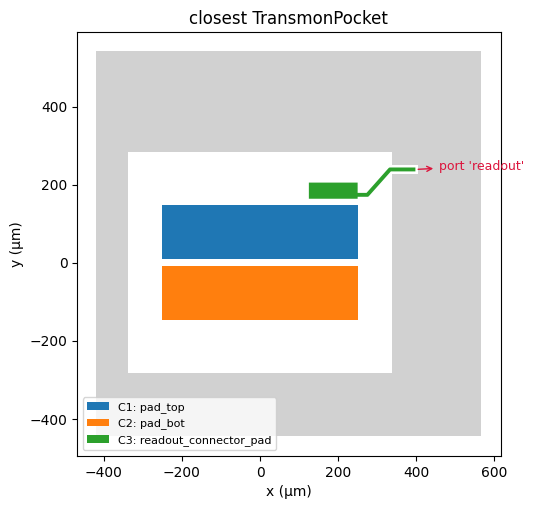

In [46]:
best_pocket = pocket_results.iloc[0]
look_at(build_component(best_pocket), "closest TransmonPocket");

In [47]:
pocket_ml = MLSimulator(analyzer, best_pocket).simulate()
C_pocket = maxwell_df(pocket_ml)
C_pocket.round(3)

,ground,pad_top,pad_bot,readout_pad
ground,189.179,-56.193,-61.100,-28.756
pad_top,-56.193,125.519,-52.692,-13.646
pad_bot,-61.100,-52.692,118.470,-1.220
readout_pad,-28.756,-13.646,-1.220,44.344


In [48]:
EC_MHz_from_matrix(C_pocket.values, C_pocket.index, ["pad_top", "pad_bot"]), 1e3 * best_pocket["EC"]

(221.99927692671767, 222.10836985197966)

### A coupler with a capacitance target: `GeneralizedCapStar`

Couplers don't have a Hamiltonian of their own, so we query them with a capacitance target directly. Let's ask for a star coupler with about 2 fF between the star and its first pad.

Some star rows (all of one collection and a few others) were labelled on a GDS that their stored options do not reproduce exactly. They carry `geometry_reproducible = False`, and we leave them out whenever we want to rebuild a design from its options.

In [49]:
db.unselect_all()
db.select_system("coupler")
db.select_coupler("GeneralizedCapStar")
star_df = db.create_system_df()
analyzer = Analyzer(db)
analyzer.df = analyzer.df[analyzer.df["geometry_reproducible"].fillna(True).astype(bool)]
len(star_df), len(analyzer.df)

(3411, 1758)

In [50]:
star_results = analyzer.find_closest({"star_to_pad_0": 2.0}, num_top=3)
star_results[["design_id", "star_to_pad_0", "star_to_ground", "pad_0_to_ground"]]

,design_id,star_to_pad_0,star_to_ground,pad_0_to_ground
1210,ref/exp11/q3d_cap_1355,2.006605,35.361054,8.802020
535,ref/exp11/q3d_cap_0593,1.985574,25.130047,10.070085
341,ref/exp11/q3d_cap_0380,2.018742,27.027778,10.493924


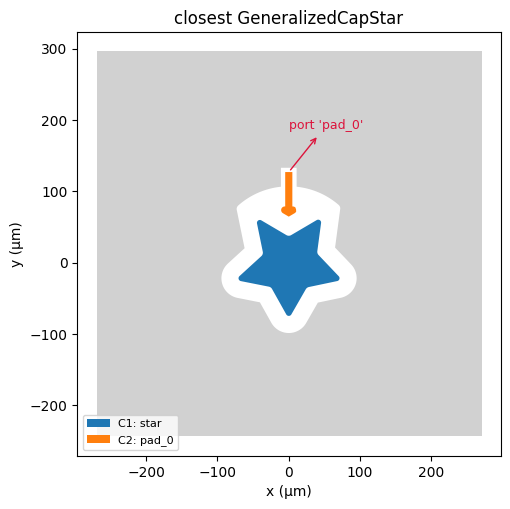

In [51]:
best_star = star_results.iloc[0]
look_at(build_component(best_star), "closest GeneralizedCapStar");

`Analyzer.predict_capacitance` predicts every row of the last `find_closest` result in one go (and works the same way on interpolated designs, as we saw above):

In [52]:
star_ml = analyzer.predict_capacitance()
star_results[["design_id", "star_to_pad_0"]].join(star_ml[["star_to_pad_0_ml", "fidelity", "ml_total_s"]])

,design_id,star_to_pad_0,star_to_pad_0_ml,fidelity,ml_total_s
1210,ref/exp11/q3d_cap_1355,2.006605,2.017028,ml:QCap,0.835758
535,ref/exp11/q3d_cap_0593,1.985574,2.000915,ml:QCap,0.809971
341,ref/exp11/q3d_cap_0380,2.018742,2.023173,ml:QCap,0.818348


These rows are training data of QCap too, so again: plumbing check, not accuracy.

### What about QCap-Fast?

There is also `QCap-Fast`, an improved release of the paper's fast model. It replaces the field solves with a learned surrogate and is roughly ten times faster, but it is only roughly right. Use it to screen many candidates of the families it was trained on and find the region of parameter space worth a closer look, then run the fine sweep there with `QCap`.

<details>
<summary><b>How much less accurate is <code>QCap-Fast</code>?</b></summary>

On new designs of a trained family, `QCap-Fast` was *worse than the physics alone*: 3.175 % (MAE 0.583 fF / RMSE 0.824 fF) against 1.765 % (MAE 0.275 fF / RMSE 0.376 fF). The paper's version of it, on a held-out family, gave 3.11 % (MAE 0.533 fF / RMSE 0.633 fF) against 1.55 % (MAE 0.166 fF / RMSE 0.205 fF). Use `QCap` for anything that matters.

</details>

In [53]:
fast_star = MLSimulator(model="QCap-Fast").predict(best_star)
fast_star["fidelity"], fast_star["sim_results"]["star_to_pad_0"], star_ml.iloc[0]["star_to_pad_0_ml"]

('ml:QCap-Fast', 1.940557599067688, 2.0170276165008545)

Finally, let's see what every prediction in this tutorial cost (wall time per design with 2 threads, on the machine this notebook ran on):

In [54]:
timing = {
    "TransmonCross (closest, repeated: cache)": ml_result["timing"]["wall_s"],
    "TransmonCross (interpolated)": interpolated_ml.iloc[0]["ml_total_s"],
    "Xmon": xmon_ml["timing"]["wall_s"],
    "TransmonPocket": pocket_ml["timing"]["wall_s"],
    "GeneralizedCapStar (QCap)": star_ml.iloc[0]["ml_total_s"],
    "GeneralizedCapStar (QCap-Fast, first call: loads the model)": fast_star["timing"]["wall_s"],
}
pd.Series(timing, name="wall time (s)").round(2)

TransmonCross (closest, repeated: cache)                       0.03
TransmonCross (interpolated)                                   1.38
Xmon                                                           1.80
TransmonPocket                                                 1.09
GeneralizedCapStar (QCap)                                      0.84
GeneralizedCapStar (QCap-Fast, first call: loads the model)    0.98
Name: wall time (s), dtype: float64

Congrats for making it to the end of this tutorial! 🤗🎉 You have now learned how to go from a set of target Hamiltonian parameters to a rendered layout, its full capacitance matrix and its Hamiltonian in about a second per design, how to check interpolated designs without a Q3D run, and how to query the new qubit and coupler families of SQuADDS. Just remember the fidelity label: an `ml:QCap` number is a prediction, and the design you send to the fab still deserves one real simulation.

## Next Steps...

In the next [tutorial](https://lfl-lab.github.io/SQuADDS/source/tutorials/Tutorial-14_Training_on_Your_Own_Designs.html), we will learn how to train the capacitance models on your own designs and simulations.

## License

<div style='width: 100%; background-color:#3cb1c2;color:#324344;padding-left: 10px; padding-bottom: 10px; padding-right: 10px; padding-top: 5px'>
    <h3>This code is a part of SQuADDS</h3>
    <p>Developed by Sadman Ahmed Shanto</p>
    <p>This tutorial is written by Sadman Ahmed Shanto and Claude Opus 5.5</p>
    <p>&copy; Copyright Sadman Ahmed Shanto & Eli Levenson-Falk 2026.</p>
    <p>This code is licensed under the MIT License. You may<br> obtain a copy of this license in the LICENSE.txt file in the root directory<br> of this source tree.</p>
    <p>Any modifications or derivative works of this code must retain this<br>copyright notice, and modified files need to carry a notice indicating<br>that they have been altered from the originals.</p>
</div>